# **Aplicación práctica: formas anatómicas 3D con la función de Christoffel–Darboux**

**Pregunta del asesor.** ¿Sirve el método con datos reales de otro dominio? Se evalúan sus dos usos con formas anatómicas:

1. **Agrupamiento (Nivel 1): «encerrar la forma».** En una escena compuesta con órganos de distintas categorías (índices de muestra coincidentes, sin correspondencia clínica demostrada), ¿se separa cada órgano? Después, ¿el conjunto de nivel del polinomio de Christoffel de cada grupo *encierra* al órgano sin invadir a los vecinos?
2. **Embedding (Nivel 2): comparar formas entre sí.** Con un descriptor por órgano orientado a ser robusto a transformaciones de pose, ¿quedan cerca los órganos del mismo tipo, aunque vengan de pacientes distintos?

### **Elección del dataset**

| Opción | Qué contiene | ¿Encaja? |
|---|---|---|
| **MedShapeNetCore** (Zenodo 10617451) | Formas anatómicas ya extraídas como máscara, **nube de puntos** y malla, en `.npz`; CC BY 4.0 | **Sí.** Ya son nubes de puntos y las etiquetas (órgano) sirven sólo para evaluar. Se usa el subconjunto **FLARE** (órganos abdominales: hígado, riñones, bazo, páncreas, aorta, vena cava, suprarrenales, vesícula, esófago, estómago, duodeno). |
| SELMA3D | Microscopía de hoja de luz de cerebros (TIFF de 16 bits; parches anotados en NIfTI); CC BY-NC | Parcial. Habría que segmentar volúmenes muy grandes antes de tener puntos; los parches anotados de núcleos o placas podrían servir para el Nivel 1 (grupos de células). Queda como extensión. |
| Human Organ Atlas | Volúmenes de tomografía de contraste de fase de órganos completos (resolución micrométrica) | No por ahora: volúmenes de gran tamaño sin segmentaciones listas; requeriría un paso de segmentación que no forma parte de la tesis. |

**Cómo citar los datos.** Li, J., Zhou, Z., Yang, J., *et al.* (2023). *MedShapeNet: A Large-Scale Dataset of 3D Medical Shapes for Computer Vision*. arXiv:2308.16139. DOI 10.5281/zenodo.10617451. Además, citar el dataset de origen (FLARE).

### **Cómo ejecutar**

1. Usar `data.npy` de fuente confiable o descargar `medshapenetcore_FLARE.npz` desde el registro de Zenodo; con el paquete oficial: `pip install MedShapeNetCore` y `python -m MedShapeNetCore download FLARE` (lo guarda en `./medshapenetcore_npz/`). También se puede activar `DESCARGAR = True` abajo.
2. Escribir la ruta del `.npy` o `.npz` en `RUTA_NPZ` (primera celda de código), o dejar `None` para la búsqueda automática.
3. Ejecutar todas las celdas en el entorno del repositorio `pointfield`. El coste de tiempo y memoria depende del hardware y de la cantidad de clases y puntos. El extractor está adaptado al formato FLARE observado (`DATA[clase]["point"]`).

Las celdas exploran el archivo y extraen sus nubes `point` por clase e índice de muestra. **No hay evidencia aquí de que los índices coincidan con IDs de paciente entre órganos**. Por ello las escenas en rejilla son sintéticas salvo verificación independiente. El notebook necesita las dependencias y módulos propios del repositorio para su ejecución completa.

In [1]:
# ===================== EDITAR AQUÍ =====================
DATASET = "FLARE"                 # subconjunto de MedShapeNetCore
RUTA_NPZ = None                   # .npz oficial; alternativa: ruta a data.npy
DESCARGAR = False                 # True: descargar .npz si no existe archivo local
N_ESCENAS = 6                     # pacientes para el Nivel 1
PUNTOS_POR_ORGANO = 400           # puntos de cada órgano dentro de la escena
GRADOS_ENVOLVENTE = (2, 4)        # grados del polinomio que "encierra" cada grupo (2: elipsoide; 4: sigue la superficie)
GRADO_FIGURA = 4                  # grado que se dibuja
PERCENTIL_ENVOLVENTE = 95         # nivel: percentil de q sobre los puntos del propio grupo
MAX_POR_CLASE = 40                # formas por órgano para el Nivel 2
N_PUNTOS = 1024                   # puntos por forma en el Nivel 2
POSE_ALEATORIA = True             # Nivel 2: quitar la posición/orientación del TAC (sólo forma)
UNIR_IZQ_DER = False              # no fusionar izquierda/derecha sin validar invariancia a reflexiones
SEMILLA = 0
# No afirmar que el índice i identifica al mismo paciente en todas las categorías sin metadatos.
INDICES_ALINEADOS_VERIFICADOS = False  # activar sólo con evidencia externa de IDs y coordenadas
MODO_ESCENA = "rejilla"               # "rejilla" o "anatomica" (requiere verificación anterior)
RESOLUCION_ENVOLVENTE = 48             # malla de visualización (mayor valor = más costoso)
GUARDAR = True                    # figuras en notebooks/figuras_aplicacion/, CSV en benchmarks/results/
# =======================================================

import os, sys, time, json, hashlib, re, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
warnings.filterwarnings("ignore", category=FutureWarning)

RAIZ = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
for p in (RAIZ / "src", RAIZ / "benchmarks"):
    if str(p) not in sys.path: sys.path.insert(0, str(p))

from pointfield.learning import (ChristoffelDarboux, CDDescriptor, CDGlobalClustering, CDLocalSpectral, BlockScaler,
                                 MultiViewMetric, moment_descriptor, moment_block_slices, make_view, paired_bootstrap)
from pointfield.learning.descriptors import d2_histogram
from pointfield.learning.evaluation import average_precision
from pointfield.geometry.mesh import TriangleMesh
from pointfield.objects import random_similarity
from common import METHODS
from objetos_invariantes import perturb
from sklearn.cluster import KMeans, AgglomerativeClustering, SpectralClustering
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, homogeneity_score, completeness_score
from sklearn.decomposition import PCA
from scipy.optimize import linear_sum_assignment

FIG = RAIZ / "notebooks" / "figuras_aplicacion"; RES = RAIZ / "benchmarks" / "results"
if GUARDAR:
    FIG.mkdir(parents=True, exist_ok=True)
    RES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
_nfig = [0]
def guardar(fig, nombre):
    if not GUARDAR: return
    _nfig[0] += 1; ruta = FIG / f"{_nfig[0]:02d}_{nombre}.png"
    fig.savefig(ruta, dpi=160, bbox_inches="tight"); print(f"[figura] {ruta.relative_to(RAIZ)}")
def tabla(df, dec=3, titulo=None):
    if titulo: display(Markdown(f"**{titulo}**"))
    display(df.round(dec) if dec is not None else df)
def rng_(k=0): return np.random.default_rng(SEMILLA + k)
print("raíz del repositorio:", RAIZ)

raíz del repositorio: /home/icantu24/Documents/PEF-CD/point-field


## **1. Localizar, descargar (opcional) y explorar el archivo**

In [2]:
# Si la lectura de un .npy confiable falla con "No module named trimesh",
# instala la dependencia en el kernel actual y reinicia el kernel antes de reintentar:
# %pip install trimesh
# Los archivos .npz/.npy con objetos pickle NO deben abrirse desde fuentes desconocidas.

In [3]:
import urllib.request

# Compatibilidad con el data.npy proporcionado; los objetos pickle requieren
# las dependencias originales (por ejemplo, trimesh). Sólo cargar fuentes confiables.
class MyDict(dict):
    pass

URL = f"https://zenodo.org/records/10623506/files/medshapenetcore_{DATASET}.npz?download=1"
nombre_npz = f"medshapenetcore_{DATASET}.npz"

def encontrar_archivo():
    candidatos = [
        RUTA_NPZ, os.environ.get("MEDSHAPENET_NPZ"),
        RAIZ / "data" / nombre_npz,
        RAIZ / "data" / "medshapenetcore_npz" / nombre_npz,
        RAIZ / "medshapenetcore_npz" / nombre_npz,
        Path.home() / "Downloads" / nombre_npz,
        Path.home() / "Descargas" / nombre_npz,
        RAIZ / "data" / "data.npy",
        Path.home() / "Downloads" / "data.npy",
        Path.home() / "Descargas" / "data.npy",
    ]
    for c in candidatos:
        if c is not None and Path(c).expanduser().is_file():
            return Path(c).expanduser().resolve()
    return None

ARCHIVO = encontrar_archivo()
if ARCHIVO is None and DESCARGAR:
    ARCHIVO = RAIZ / "data" / nombre_npz
    ARCHIVO.parent.mkdir(parents=True, exist_ok=True)
    print("Descargando:", URL)
    urllib.request.urlretrieve(URL, ARCHIVO)
assert ARCHIVO is not None, (
    "Archivo no encontrado: especifica RUTA_NPZ (acepta .npy o .npz), "
    "sitúa data.npy en ~/Downloads o activa DESCARGAR."
)
print("Archivo:", ARCHIVO, "tamaño (GiB):", round(ARCHIVO.stat().st_size / 2**30, 2))

t0 = time.perf_counter()
if ARCHIVO.suffix.lower() == ".npz":
    with np.load(ARCHIVO, allow_pickle=True) as z:
        if "data" in z.files:
            DATA = z["data"]
        else:
            DATA = {k: z[k] for k in z.files}
elif ARCHIVO.suffix.lower() == ".npy":
    DATA = np.load(ARCHIVO, allow_pickle=True)
else:
    raise ValueError(f"Extensión no compatible: {ARCHIVO.suffix}")
if isinstance(DATA, np.ndarray) and DATA.ndim == 0 and DATA.dtype == object:
    DATA = DATA.item()
print(f"Cargado en {time.perf_counter()-t0:.1f} s; tipo: {type(DATA).__name__}")

def describir(obj, nivel=0, max_claves=14, max_nivel=4):
    pre = "    " * nivel
    if isinstance(obj, dict):
        keys = list(obj.keys())
        print(f"{pre}dict con {len(keys)} claves")
        if nivel < max_nivel:
            for k in keys[:max_claves]:
                print(f"{pre}  [{k!r}]")
                describir(obj[k], nivel+1, max_claves, max_nivel)
            if len(keys) > max_claves:
                print(f"{pre}  ... ({len(keys)-max_claves} claves adicionales)")
    elif isinstance(obj, np.ndarray):
        print(f"{pre}ndarray {obj.shape} dtype={obj.dtype}")
        if obj.dtype == object and obj.size and nivel < max_nivel:
            describir(obj.item() if obj.ndim == 0 else obj.flat[0],
                      nivel+1, max_claves, max_nivel)
    elif isinstance(obj, (list, tuple)):
        print(f"{pre}{type(obj).__name__} de {len(obj)} elementos")
        if len(obj) and nivel < max_nivel:
            describir(obj[0], nivel+1, max_claves, max_nivel)
    elif hasattr(obj, "vertices") and hasattr(obj, "faces"):
        print(f"{pre}malla: V={np.asarray(obj.vertices).shape}, F={np.asarray(obj.faces).shape}")
    else:
        print(f"{pre}{type(obj).__name__}: {str(obj)[:70]}")

describir(DATA, max_claves=5, max_nivel=3)

Archivo: /home/icantu24/Downloads/medshapenetcore_FLARE.npz tamaño (GiB): 0.54
Cargado en 214.4 s; tipo: MyDict
dict con 13 claves
  ['liver']
    dict con 3 claves
      ['mask']
        ndarray (50, 256, 256, 256) dtype=int16
      ['point']
        ndarray (50, 65536, 3) dtype=float64
      ['mesh']
        dict con 2 claves
          ['vertices']
            ndarray (50,) dtype=object
          ['faces']
            ndarray (50, 65536, 3) dtype=int16
  ['right_kidney']
    dict con 3 claves
      ['mask']
        ndarray (50, 256, 256, 256) dtype=int16
      ['point']
        ndarray (50, 65536, 3) dtype=float64
      ['mesh']
        dict con 2 claves
          ['vertices']
            ndarray (50,) dtype=object
          ['faces']
            ndarray (50,) dtype=object
  ['spleen']
    dict con 3 claves
      ['mask']
        ndarray (50, 256, 256, 256) dtype=int16
      ['point']
        ndarray (50, 65536, 3) dtype=float64
      ['mesh']
        dict con 2 claves
          ['ve

## **2. Extraer las nubes `point` de FLARE y auditar la estructura**

El archivo observado contiene categorías anatómicas como `liver` y `right_kidney`, cada una con `point` de forma `(50, 65536, 3)`. Se da **prioridad exclusiva a estas nubes**, sin recorrer máscaras volumétricas ni mallas (las caras almacenadas como `int16` pueden requerir una revisión de índices antes de convertirse a malla). Se retienen identificadores de **índice de muestra**, no IDs clínicos verificados.

El muestreo se hace por forma sin reconstruir ni cargar geometrías intermedias adicionales. Los índices de muestra **no acreditan** que dos órganos correspondan a un mismo paciente.

In [4]:
# Esta ruta está adaptada al formato FLARE observado: DATA[clase]["point"] = (M,N,3).
# Si el archivo es distinto, fallar con información clara, no reinterpretar máscaras.
if not isinstance(DATA, dict):
    raise TypeError("Se esperaba dict[órgano]['point'] con nubes (muestras, puntos, 3).")

r_muestreo = rng_(1)
FORMAS = []
CAT_FILAS = []
for clase, contenido in DATA.items():
    if not isinstance(contenido, dict) or "point" not in contenido:
        print(f"[omitido] {clase}: no tiene clave 'point'")
        continue
    nube_clase = contenido["point"]
    if getattr(nube_clase, "ndim", None) != 3 or nube_clase.shape[-1] != 3:
        print(f"[omitido] {clase}: point.shape={getattr(nube_clase, 'shape', None)}")
        continue
    for indice in range(nube_clase.shape[0]):
        X = np.asarray(nube_clase[indice], dtype=np.float64)
        X = X[np.isfinite(X).all(axis=1)]
        if len(X) < 50:
            continue
        # Mantener hasta N_PUNTOS para descriptor y hasta PUNTOS_POR_ORGANO para escenas.
        n_base = min(len(X), max(N_PUNTOS, PUNTOS_POR_ORGANO, 2500))
        ix = r_muestreo.choice(len(X), n_base, replace=False)
        X = X[ix]
        if np.ptp(X, axis=0).max() <= 0:
            continue
        ident = str(indice)  # índice, NO identificador verificado de paciente
        FORMAS.append({"clase": str(clase), "paciente": ident, "formato": "point", "X": X})
        CAT_FILAS.append({"clase": str(clase), "paciente": ident, "formato": "point",
                          "n_puntos": len(X), "extensión": float(np.ptp(X, axis=0).max())})

if not FORMAS:
    raise ValueError("No se extrajeron nubes 3D válidas de DATA[clase]['point'].")
CAT = pd.DataFrame(CAT_FILAS)
resumen = CAT.groupby("clase").agg(
    formas=("paciente", "size"), formato=("formato", "first"),
    puntos_mediana=("n_puntos", "median"), extensión_mediana=("extensión", "median")
)
tabla(resumen, 1, f"{DATASET}: {len(FORMAS)} formas en {len(resumen)} clases")
assert len(resumen) >= 2, "Se requieren al menos dos clases para comparar recuperación."
assert (CAT.groupby(["clase", "paciente"]).size() == 1).all(), "Índices duplicados por órgano"

**FLARE: 628 formas en 13 clases**

,formas,formato,puntos_mediana,extensión_mediana
clase,,,,
aorta,50,point,2500.0,75.0
duodenum,43,point,2500.0,126.7
esophagus,50,point,2500.0,54.2
gallbladder,50,point,2500.0,74.4
inferior_vena_cava,50,point,2500.0,66.5
left_adrenal_gland,50,point,2500.0,48.3
left_kidney,38,point,2500.0,78.0
liver,50,point,2500.0,258.2
pancreas,50,point,2500.0,119.5


## **3. Galería y comprobaciones exploratorias de coordenadas**

El gráfico permite inspeccionar cada forma. Una relación alta entre distancias de centroides y radios de los órganos **no demuestra** que los índices representen el mismo paciente o compartan un mismo marco anatómico. Por ello el Nivel 1 utilizará **escenas sintéticas en rejilla por defecto**; solo se habilitan escenas anatómicas cuando se comprueben IDs, alineación y procedencia desde metadatos externos.

[figura] notebooks/figuras_aplicacion/01_galeria_clases.png


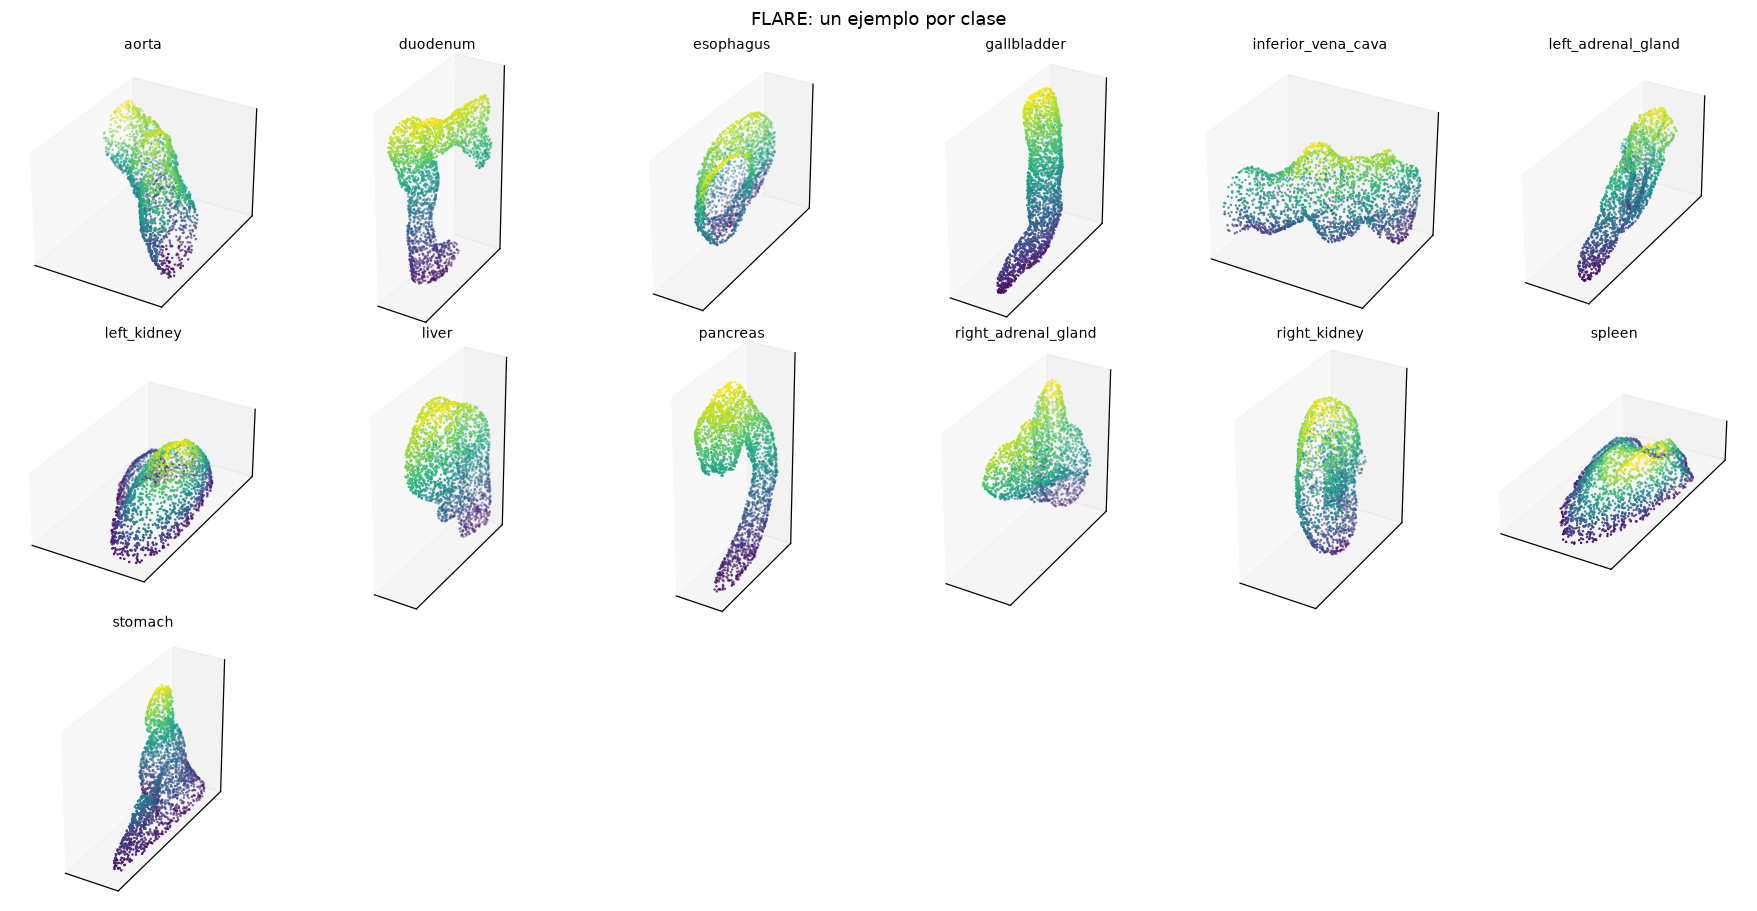

Índices con >=3 órganos: 50 (identidad clínica NO verificada)
Relación mediana distancia/radio exploratoria: 3.115682991593061


**Nivel 1:** escenas compuestas artificialmente en rejilla (no son escenas anatómicas reales)

In [5]:
clases = list(resumen.index)
cols = min(6, len(clases)); filas = int(np.ceil(len(clases) / cols))
fig = plt.figure(figsize=(2.7 * cols, 2.8 * filas))
for i, c in enumerate(clases):
    X = next(f["X"] for f in FORMAS if f["clase"] == c)
    X = X[rng_(2).choice(len(X), min(len(X), 2500), replace=False)]
    a = fig.add_subplot(filas, cols, i + 1, projection="3d"); a.scatter(*X.T, s=0.4, c=X[:, 2], cmap="viridis")
    a.set_box_aspect(np.ptp(X, axis=0) / np.ptp(X, axis=0).max()); a.set_xticks([]); a.set_yticks([]); a.set_zticks([])
    a.set_title(c, fontsize=9)
fig.suptitle(f"{DATASET}: un ejemplo por clase"); plt.tight_layout(); guardar(fig, "galeria_clases"); plt.show()

# Solo diagnóstico geométrico, NO validación de IDs ni registro espacial.
por_paciente = CAT.groupby("paciente").clase.nunique().sort_values(ascending=False)
razones = []
for p in por_paciente.index[:20]:
    F = [f["X"] for f in FORMAS if f["paciente"] == p]
    if len(F) < 3: continue
    C = np.array([X.mean(0) for X in F])
    radios = [np.sqrt(np.mean(np.sum((X - X.mean(0))**2, axis=1))) for X in F]
    r = np.median(radios)
    d = np.linalg.norm(C[:, None] - C[None], axis=-1)
    razones.append(float(np.median(d[np.triu_indices(len(C), 1)]) / max(r, 1e-12)))
print(f"Índices con >=3 órganos: {(por_paciente >= 3).sum()} (identidad clínica NO verificada)")
print("Relación mediana distancia/radio exploratoria:", np.median(razones) if razones else np.nan)
assert MODO_ESCENA in ("rejilla", "anatomica")
if MODO_ESCENA == "anatomica" and not INDICES_ALINEADOS_VERIFICADOS:
    raise ValueError("No se puede usar MODO_ESCENA='anatomica' sin verificar IDs y coordenadas.")
ALINEADO = MODO_ESCENA == "anatomica" and INDICES_ALINEADOS_VERIFICADOS
display(Markdown("**Nivel 1:** " + ("escenas anatómicas verificadas" if ALINEADO else
    "escenas compuestas artificialmente en rejilla (no son escenas anatómicas reales)")))

---
## **4. Nivel 1 — agrupar los órganos de un paciente y «encerrar» cada forma**

Se agrupan nubes de órganos con el mismo **índice de archivo**, que no equivale a un ID clínico comprobado. Cada órgano aporta `PUNTOS_POR_ORGANO` puntos; por defecto se sitúan en una rejilla artificial, se normaliza la escena (centro y radio RMS) y se agrupa **sin etiquetas** con los mismos métodos y configuraciones de la tesis (§5.4), con $K$ = número de órganos del paciente. Las etiquetas sólo se usan al final para ARI, NMI, homogeneidad y completitud.

In [6]:
METODOS_N1 = {k: v for k, v in METHODS.items() if "Szegő" not in k}   # la fase V2 sólo está definida en 2D
NOMBRE_CORTO = {"CD global (inicial)": "V0 · CD global", "CD local-espectral (mejora 1)": "V1 · CD local", "Spectral (kNN)": "Espectral k-NN"}

def escena(paciente, rng):
    """Escena sintética por índice de archivo, salvo validación anatómica externa."""
    F = sorted([f for f in FORMAS if f["paciente"] == paciente], key=lambda f: f["clase"])
    Xs, ys, nombres = [], [], []
    for j, f in enumerate(F):
        X = f["X"][rng.choice(len(f["X"]), min(PUNTOS_POR_ORGANO, len(f["X"])), replace=False)]
        if not ALINEADO:   # composición en rejilla: cada forma normalizada y desplazada
            X = (X - X.mean(0)) / max(np.sqrt(((X - X.mean(0)) ** 2).sum(1).mean()), 1e-12) + 5.0 * np.array([j % 4, j // 4, 0.0])
        Xs.append(X); ys.append(np.full(len(X), j)); nombres.append(f["clase"])
    X = np.vstack(Xs); X = (X - X.mean(0)) / max(np.sqrt(((X - X.mean(0)) ** 2).sum(1).mean()), 1e-12)
    return X, np.concatenate(ys), nombres

PACIENTES = [p for p in por_paciente.index if por_paciente[p] >= 3][:N_ESCENAS]
assert PACIENTES, "No hay índices de muestra con al menos tres clases."
filas, ESCENAS = [], {}
for p in PACIENTES:
    X, y, nombres = escena(p, rng_(3)); K = len(nombres); ESCENAS[p] = {"X": X, "y": y, "nombres": nombres, "pred": {}}
    for m, (fabrica, _, _, _) in METODOS_N1.items():
        t0 = time.perf_counter(); lab = np.asarray(fabrica(K).fit_predict(X)); dt = time.perf_counter() - t0
        ESCENAS[p]["pred"][m] = lab
        filas.append({"indice_muestra": p, "tipo_escena": "anatomica_verificada" if ALINEADO else "rejilla_sintetica", "órganos": K, "puntos": len(X), "método": NOMBRE_CORTO.get(m, m), "ARI": adjusted_rand_score(y, lab),
                      "NMI": normalized_mutual_info_score(y, lab), "homogeneidad": homogeneity_score(y, lab),
                      "completitud": completeness_score(y, lab), "tiempo (s)": dt})
N1 = pd.DataFrame(filas)
tabla(N1.pivot_table(index="indice_muestra", columns="método", values="ARI"), 2, "Nivel 1 · ARI por índice de muestra")
tabla(N1.groupby("método")[["ARI", "NMI", "homogeneidad", "completitud", "tiempo (s)"]].agg(["mean", "std"]).sort_values(("ARI", "mean"), ascending=False),
      3, f"Nivel 1 · promedio sobre {len(PACIENTES)} índices de muestra")

**Nivel 1 · ARI por índice de muestra**

método,DBSCAN,Espectral k-NN,K-Means,OPTICS,V0 · CD global,V1 · CD local
indice_muestra,,,,,,
0,0.94,1.0,1.0,0.57,1.0,1.0
1,0.97,1.0,1.0,0.41,1.0,1.0
10,0.90,1.0,1.0,0.41,1.0,1.0
11,0.96,1.0,1.0,0.48,1.0,1.0
12,0.92,1.0,1.0,0.41,1.0,1.0
13,0.95,1.0,1.0,0.57,1.0,1.0


**Nivel 1 · promedio sobre 6 índices de muestra**

ARI           NMI        homogeneidad        completitud  \
                 mean    std   mean    std         mean    std        mean   
método                                                                       
Espectral k-NN  1.000  0.000  1.000  0.000        1.000  0.000       1.000   
K-Means         1.000  0.000  1.000  0.000        1.000  0.000       1.000   
V1 · CD local   1.000  0.000  1.000  0.000        1.000  0.000       1.000   
V0 · CD global  1.000  0.000  1.000  0.000        1.000  0.000       1.000   
DBSCAN          0.941  0.025  0.951  0.017        0.990  0.004       0.915   
OPTICS          0.478  0.079  0.773  0.037        0.631  0.050       1.000   

                      tiempo (s)         
                  std       mean    std  
método                                   
Espectral k-NN  0.000      0.160  0.016  
K-Means         0.000      0.050  0.013  
V1 · CD local   0.000      2.995  1.198  
V0 · CD global  0.000      0.085  0.017  
DBSCAN          0.029      0.045  0.003  
OPTICS          0.000      4.505  0.169

[figura] notebooks/figuras_aplicacion/02_nivel1_escena.png


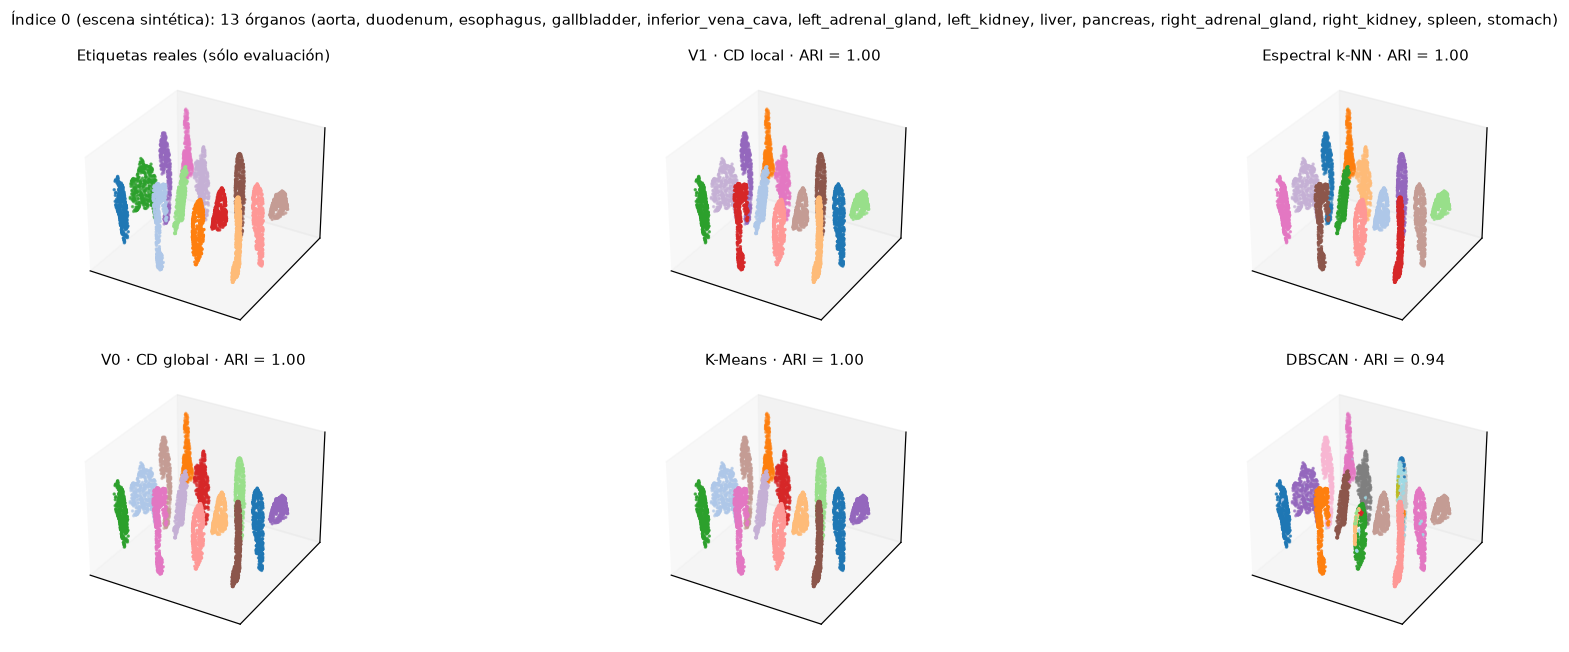

In [7]:
p0 = PACIENTES[0]; E = ESCENAS[p0]
mostrar = ["verdad", "CD local-espectral (mejora 1)", "Spectral (kNN)", "CD global (inicial)", "K-Means", "DBSCAN"]
fig = plt.figure(figsize=(18, 6))
for i, m in enumerate(mostrar):
    lab = E["y"] if m == "verdad" else E["pred"][m]
    a = fig.add_subplot(2, 3, i + 1, projection="3d"); a.scatter(*E["X"].T, color=plt.get_cmap("tab20")(lab % 20), s=1.5)
    t = "Etiquetas reales (sólo evaluación)" if m == "verdad" else f"{NOMBRE_CORTO.get(m, m)} · ARI = {adjusted_rand_score(E['y'], lab):.2f}"
    a.set_title(t, fontsize=10); a.set_xticks([]); a.set_yticks([]); a.set_zticks([])
fig.suptitle(f"Índice {p0} (escena {"anatómica" if ALINEADO else "sintética"}): {len(E['nombres'])} órganos ({', '.join(E['nombres'])})", fontsize=10)
plt.tight_layout(); guardar(fig, "nivel1_escena"); plt.show()

### **4.1 «Aproximar el soporte por subnivel»: envolvente de Christoffel de cada grupo**

Para cada grupo encontrado por V1 se ajusta un polinomio de Christoffel de grado 2 y de grado 4 (`GRADOS_ENVOLVENTE`) (normalizado por grupo, regularización $c = 10^{-6}$) y se define su envolvente como el conjunto de subnivel $\{x : q(x) \le \gamma\}$, con $\gamma$ el percentil `PERCENTIL_ENVOLVENTE` de $q$ sobre los puntos del propio grupo (§2.6.4). Se mide:

- **cobertura**: fracción de los puntos del órgano real asociado (asignación húngara) que quedan dentro de la envolvente;
- **invasión**: fracción de los puntos *de otros órganos* que quedan dentro de la envolvente;
- **pureza**: de los puntos que la envolvente encierra, fracción que pertenece a su órgano.

La misma medición con los grupos reales en lugar de los de V1 da la referencia de qué tan bien puede encerrar el polinomio a cada órgano. Con grado 2 la envolvente es un elipsoide que encierra todo el órgano (incluido su interior, si los puntos son de superficie); con grado 4 se ciñe a la forma, como se vio en §6.9.

Las métricas sobre puntos utilizados para ajustar la envolvente son **de entrenamiento** y pueden ser optimistas. Las superficies de nivel son aproximaciones polinomiales, no necesariamente superficies anatómicas precisas.

In [8]:
def envolventes(X, lab, grado):
    "Ajusta un modelo CD por grupo; devuelve el modelo, la normalización y el umbral."
    out = {}
    for g in np.unique(lab):
        if g < 0 or (lab == g).sum() < 50: continue
        Z = X[lab == g]; c = Z.mean(0); r = np.sqrt(((Z - c) ** 2).sum(1).mean())
        cd = ChristoffelDarboux(degree=grado, reg=1e-6).fit((Z - c) / r)
        out[g] = (cd, c, r, np.percentile(cd.score((Z - c) / r), PERCENTIL_ENVOLVENTE))
    return out
def dentro(env, X):
    return {g: cd.score((X - c) / r) <= gam for g, (cd, c, r, gam) in env.items()}

def medir_envolventes(X, y, lab, grado):
    env = envolventes(X, lab, grado); D = dentro(env, X)
    gs = list(env); ys = np.unique(y)
    if not gs:
        return pd.DataFrame(columns=["órgano", "cobertura", "invasión", "pureza"]), env
    C = np.array([[np.sum((y == t) & (lab == g)) for g in gs] for t in ys])
    fi, co = linear_sum_assignment(-C)
    filas = []
    for t, j in zip(ys[fi], co):
        g = gs[j]; ins = D[g]
        filas.append({"órgano": t, "cobertura": ins[y == t].mean(), "invasión": ins[y != t].mean(),
                      "pureza": (y[ins] == t).mean() if ins.any() else np.nan})
    return pd.DataFrame(filas), env

filas = []
for p, E in ESCENAS.items():
    for grado in GRADOS_ENVOLVENTE:
        for fuente, lab in (("grupos reales", E["y"]), ("grupos de V1", E["pred"]["CD local-espectral (mejora 1)"])):
            T, _ = medir_envolventes(E["X"], E["y"], lab, grado); T["indice_muestra"] = p; T["grupos"] = fuente; T["grado"] = grado
            T["órgano"] = [E["nombres"][t] for t in T["órgano"]]; filas.append(T)
ENV = pd.concat(filas, ignore_index=True) if filas else pd.DataFrame()
assert not ENV.empty, "No se pudieron ajustar envolventes: comprobar tamaño de los grupos."
tabla(ENV[ENV.grado == GRADO_FIGURA].groupby(["grupos", "órgano"])[["cobertura", "invasión", "pureza"]].mean().unstack(0), 3,
      f"Envolventes de grado {GRADO_FIGURA} por órgano (promedio sobre índices)")
tabla(ENV.groupby(["grado", "grupos"])[["cobertura", "invasión", "pureza"]].agg(["mean", "std"]), 3, "Envolventes: resumen por grado")

**Envolventes de grado 4 por órgano (promedio sobre índices)**

cobertura                   invasión                \
grupos              grupos de V1 grupos reales grupos de V1 grupos reales   
órgano                                                                      
aorta                       0.95          0.95          0.0           0.0   
duodenum                    0.95          0.95          0.0           0.0   
esophagus                   0.95          0.95          0.0           0.0   
gallbladder                 0.95          0.95          0.0           0.0   
inferior_vena_cava          0.95          0.95          0.0           0.0   
left_adrenal_gland          0.95          0.95          0.0           0.0   
left_kidney                 0.95          0.95          0.0           0.0   
liver                       0.95          0.95          0.0           0.0   
pancreas                    0.95          0.95          0.0           0.0   
right_adrenal_gland         0.95          0.95          0.0           0.0   
right_kidney                0.95          0.95          0.0           0.0   
spleen                      0.95          0.95          0.0           0.0   
stomach                     0.95          0.95          0.0           0.0   

                          pureza                
grupos              grupos de V1 grupos reales  
órgano                                          
aorta                        1.0           1.0  
duodenum                     1.0           1.0  
esophagus                    1.0           1.0  
gallbladder                  1.0           1.0  
inferior_vena_cava           1.0           1.0  
left_adrenal_gland           1.0           1.0  
left_kidney                  1.0           1.0  
liver                        1.0           1.0  
pancreas                     1.0           1.0  
right_adrenal_gland          1.0           1.0  
right_kidney                 1.0           1.0  
spleen                       1.0           1.0  
stomach                      1.0           1.0

**Envolventes: resumen por grado**

cobertura      invasión      pureza     
                         mean  std     mean  std   mean  std
grado grupos                                                
2     grupos de V1       0.95  0.0      0.0  0.0    1.0  0.0
      grupos reales      0.95  0.0      0.0  0.0    1.0  0.0
4     grupos de V1       0.95  0.0      0.0  0.0    1.0  0.0
      grupos reales      0.95  0.0      0.0  0.0    1.0  0.0

In [9]:
%pip install scikit-image


[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


[figura] notebooks/figuras_aplicacion/03_nivel1_envolventes.png


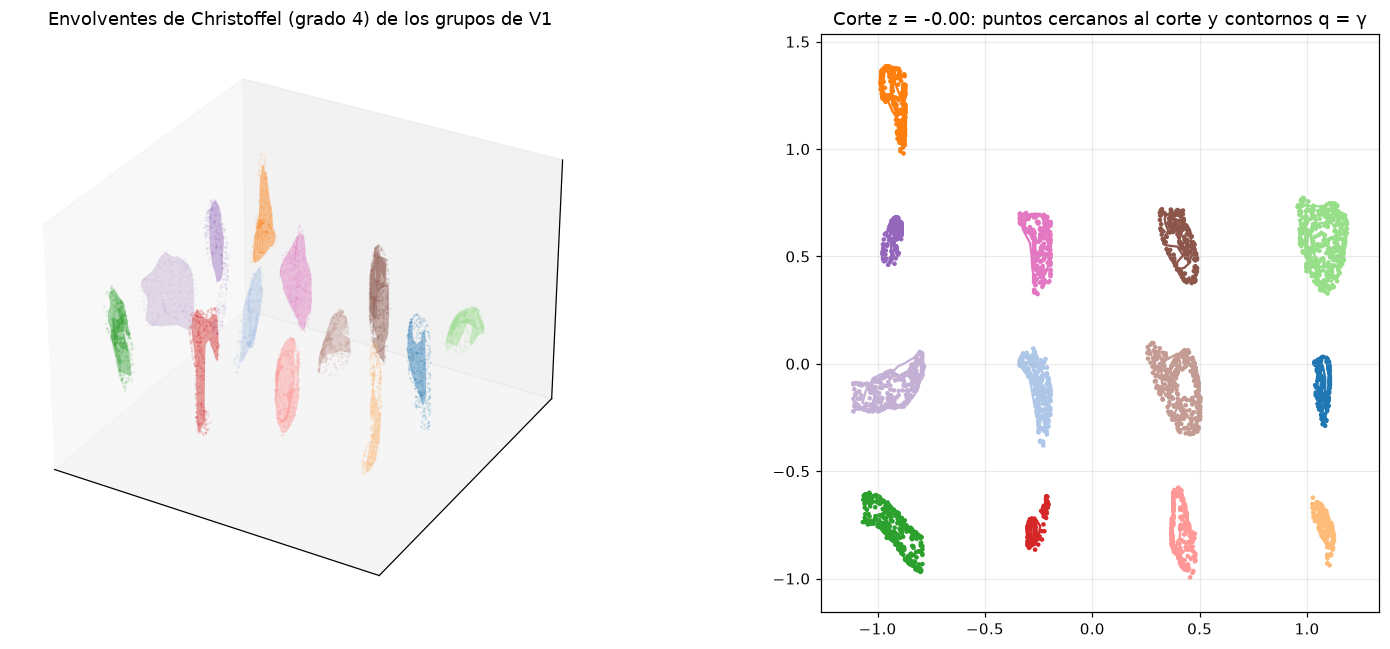

In [10]:
from skimage.measure import marching_cubes
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
E = ESCENAS[p0]; lab = E["pred"]["CD local-espectral (mejora 1)"]; env = envolventes(E["X"], lab, GRADO_FIGURA)
lo, hi = E["X"].min(0) - 0.15, E["X"].max(0) + 0.15; n = RESOLUCION_ENVOLVENTE
g1 = [np.linspace(lo[i], hi[i], n) for i in range(3)]; G = np.stack(np.meshgrid(*g1, indexing="ij"), -1).reshape(-1, 3)
fig = plt.figure(figsize=(15, 6)); a = fig.add_subplot(1, 2, 1, projection="3d"); b = fig.add_subplot(1, 2, 2)
cmap = plt.get_cmap("tab20")
for g, (cd, c, r, gam) in env.items():
    S = np.log10(np.maximum(cd.score((G - c) / r), 1e-300)).reshape(n, n, n)
    try:
        V, Fc, _, _ = marching_cubes(S, np.log10(max(gam, 1e-300)), spacing=tuple((hi - lo) / (n - 1)))
        a.add_collection3d(Poly3DCollection(V[Fc] + lo, alpha=0.25, facecolor=cmap(g % 20), edgecolor="none"))
    except (ValueError, RuntimeError):
        pass
    k = n // 2; b.contour(g1[0], g1[1], S[:, :, k].T, levels=[np.log10(max(gam, 1e-300))], colors=[cmap(g % 20)])
a.scatter(*E["X"].T, color=cmap(lab % 20), s=0.3, alpha=0.4); a.set_xlim(lo[0], hi[0]); a.set_ylim(lo[1], hi[1]); a.set_zlim(lo[2], hi[2])
a.set_title(f"Envolventes de Christoffel (grado {GRADO_FIGURA}) de los grupos de V1"); a.set_xticks([]); a.set_yticks([]); a.set_zticks([])
zc = g1[2][n // 2]; m_ = np.abs(E["X"][:, 2] - zc) < 0.08
b.scatter(E["X"][m_, 0], E["X"][m_, 1], color=cmap(lab[m_] % 20), s=4); b.set_aspect("equal")
b.set_title(f"Corte z = {zc:.2f}: puntos cercanos al corte y contornos q = γ")
plt.tight_layout(); guardar(fig, "nivel1_envolventes"); plt.show()

---
## **5. Nivel 2 — embedding de formas: ¿se acercan los órganos del mismo tipo?**

Cada forma se describe con 1 024 puntos. Con `POSE_ALEATORIA = True` se aplica la transformación implementada por `random_similarity` para explorar robustez frente a cambios de pose. No se presupone invariancia exacta sin una prueba independiente. Se comparan los descriptores de la tesis: `CD_U` (Christoffel–Darboux), `M_U` (momentos, control) y D2 (distancias entre pares), cada uno sin y con la métrica multivista aprendida **sin etiquetas** (§4.4).

La fusión de órganos izquierdos y derechos (`UNIR_IZQ_DER`) está desactivada por defecto: exige verificar que la reflexión se maneja de forma adecuada y justificar biológicamente esa etiqueta conjunta.

**Diseño del experimento:** la transformación de datos y el ajuste no supervisado de la métrica usan el conjunto de formas evaluado; por ello la recuperación leave-one-out aquí es **transductiva**, no una evaluación inductiva sobre pacientes inéditos. Fusionar órganos izquierdos y derechos tampoco está justificado solo por invariancia a rotación/escala: requiere estudiar reflexión.

In [11]:
def clase_n2(c):
    if not UNIR_IZQ_DER: return c
    return re.sub(r"[_\s-]*(left|right|izquierd[oa]|derech[oa]|_l$|_r$|\bl\b|\br\b)", "", c, flags=re.I).strip("_ -") or c

r2 = rng_(5); SEL = []
for c in clases:
    F = [f for f in FORMAS if f["clase"] == c]
    for i in r2.permutation(len(F))[:MAX_POR_CLASE]: SEL.append(F[i])
NUBES, Y_TXT = [], []
for f in SEL:
    X = f["X"][r2.choice(len(f["X"]), N_PUNTOS, replace=len(f["X"]) < N_PUNTOS)]
    NUBES.append(random_similarity(X, r2) if POSE_ALEATORIA else X); Y_TXT.append(clase_n2(f["clase"]))
CLASES2 = sorted(set(Y_TXT)); Y2 = np.array([CLASES2.index(c) for c in Y_TXT])
tabla(pd.Series(Y_TXT).value_counts().rename("formas").to_frame(), 0, f"Nivel 2: {len(NUBES)} formas, {len(CLASES2)} clases")
assert len(CLASES2) >= 2 and min(np.bincount(Y2)) >= 2, "Se requieren >=2 formas por clase para AP leave-one-out."

t0 = time.time()
cd = CDDescriptor()
F_ = {"CD_U": np.array([cd(x) for x in NUBES]), "M_U": np.array([moment_descriptor(x) for x in NUBES]),
      "D2": np.array([d2_histogram(x) for x in NUBES])}
sc = {"CD_U": BlockScaler(cd.block_slices(3)).fit(F_["CD_U"]), "M_U": BlockScaler(moment_block_slices(3)).fit(F_["M_U"])}
vistas = [[make_view(x, r2) for _ in range(4)] for x in NUBES]
VV = {"CD_U": np.array([[sc["CD_U"].transform(cd(v)) for v in vs] for vs in vistas]),
      "M_U": np.array([[sc["M_U"].transform(moment_descriptor(v)) for v in vs] for vs in vistas])}
MET = {k: MultiViewMetric(seed=SEMILLA).fit(VV[k]) for k in VV}
EMB = {"CD_U": sc["CD_U"].transform(F_["CD_U"]), "M_U": sc["M_U"].transform(F_["M_U"]), "D2": F_["D2"]}
for k in MET: EMB[f"{k}+m"] = MET[k].transform(EMB[k])
print(f"descriptores y métricas en {time.time() - t0:.0f} s; η elegido sin etiquetas:", {k: m.eta_ for k, m in MET.items()})

**Nivel 2: 518 formas, 13 clases**

,formas
aorta,40
duodenum,40
esophagus,40
gallbladder,40
inferior_vena_cava,40
left_adrenal_gland,40
liver,40
pancreas,40
right_adrenal_gland,40
right_kidney,40


descriptores y métricas en 143 s; η elegido sin etiquetas: {'CD_U': 0.1, 'M_U': 0.1}


In [12]:
def ap_loo(F, y):
    "AP de cada forma consultando contra todas las demás (se excluye a sí misma)."
    from sklearn.metrics import pairwise_distances
    D = pairwise_distances(F, metric="euclidean")
    np.fill_diagonal(D, np.inf)
    ap = np.array([average_precision(D[i][np.arange(len(y)) != i], (y == y[i])[np.arange(len(y)) != i]) for i in range(len(y))])
    nn = (y[np.argmin(D, axis=1)] == y).mean()
    return ap, nn, D

AP, filas = {}, []
for m, F in EMB.items():
    ap, nn, D = ap_loo(F, Y2); AP[m] = ap
    intra = np.mean([D[i, (Y2 == Y2[i]) & (np.arange(len(Y2)) != i)].mean() for i in range(len(Y2))])
    inter = np.mean([D[i, Y2 != Y2[i]].mean() for i in range(len(Y2))])
    filas.append({"descriptor": m, "mAP": np.nanmean(ap), "1-NN": nn, "distancia intra / inter": intra / inter})
N2 = pd.DataFrame(filas).set_index("descriptor").sort_values("mAP", ascending=False)
tabla(N2, 3, f"Nivel 2 · recuperación dejando una fuera (azar ≈ 1/{len(CLASES2)})")
filas = []
for a, b in (("CD_U+m", "M_U+m"), ("CD_U+m", "D2"), ("CD_U", "M_U")):
    bs = paired_bootstrap(AP[a], AP[b], strata=Y2, n_boot=3000, seed=SEMILLA)
    filas.append({"contraste": f"{a} − {b}", "Δ mAP": bs["diff"], "IC bajo": bs["ci_low"], "IC alto": bs["ci_high"],
                  "lectura": "CD mejor" if bs["ci_low"] > 0 else ("CD peor" if bs["ci_high"] < 0 else "sin diferencia")})
CONTRASTES2 = pd.DataFrame(filas).set_index("contraste"); tabla(CONTRASTES2, 3, "Contrastes con IC bootstrap al 95 % (estratificado por clase)")
tabla(pd.DataFrame({m: pd.Series(AP[m]).groupby(np.array(CLASES2)[Y2]).mean() for m in ("D2", "M_U+m", "CD_U+m")}), 3, "AP medio por clase")

**Nivel 2 · recuperación dejando una fuera (azar ≈ 1/13)**

,mAP,1-NN,distancia intra / inter
descriptor,,,
CD_U+m,0.326,0.625,0.814
M_U+m,0.282,0.554,0.827
M_U,0.264,0.550,0.773
CD_U,0.259,0.558,0.809
D2,0.201,0.317,0.769


**Contrastes con IC bootstrap al 95 % (estratificado por clase)**

,Δ mAP,IC bajo,IC alto,lectura
contraste,,,,
CD_U+m − M_U+m,0.044,0.038,0.050,CD mejor
CD_U+m − D2,0.125,0.115,0.135,CD mejor
CD_U − M_U,-0.004,-0.009,0.001,sin diferencia


**AP medio por clase**

,D2,M_U+m,CD_U+m
aorta,0.209,0.300,0.299
duodenum,0.219,0.215,0.251
esophagus,0.123,0.215,0.303
gallbladder,0.139,0.223,0.325
inferior_vena_cava,0.166,0.354,0.365
left_adrenal_gland,0.163,0.158,0.197
left_kidney,0.135,0.151,0.145
liver,0.365,0.651,0.754
pancreas,0.158,0.210,0.250
right_adrenal_gland,0.198,0.257,0.328


[figura] notebooks/figuras_aplicacion/04_nivel2_embedding.png


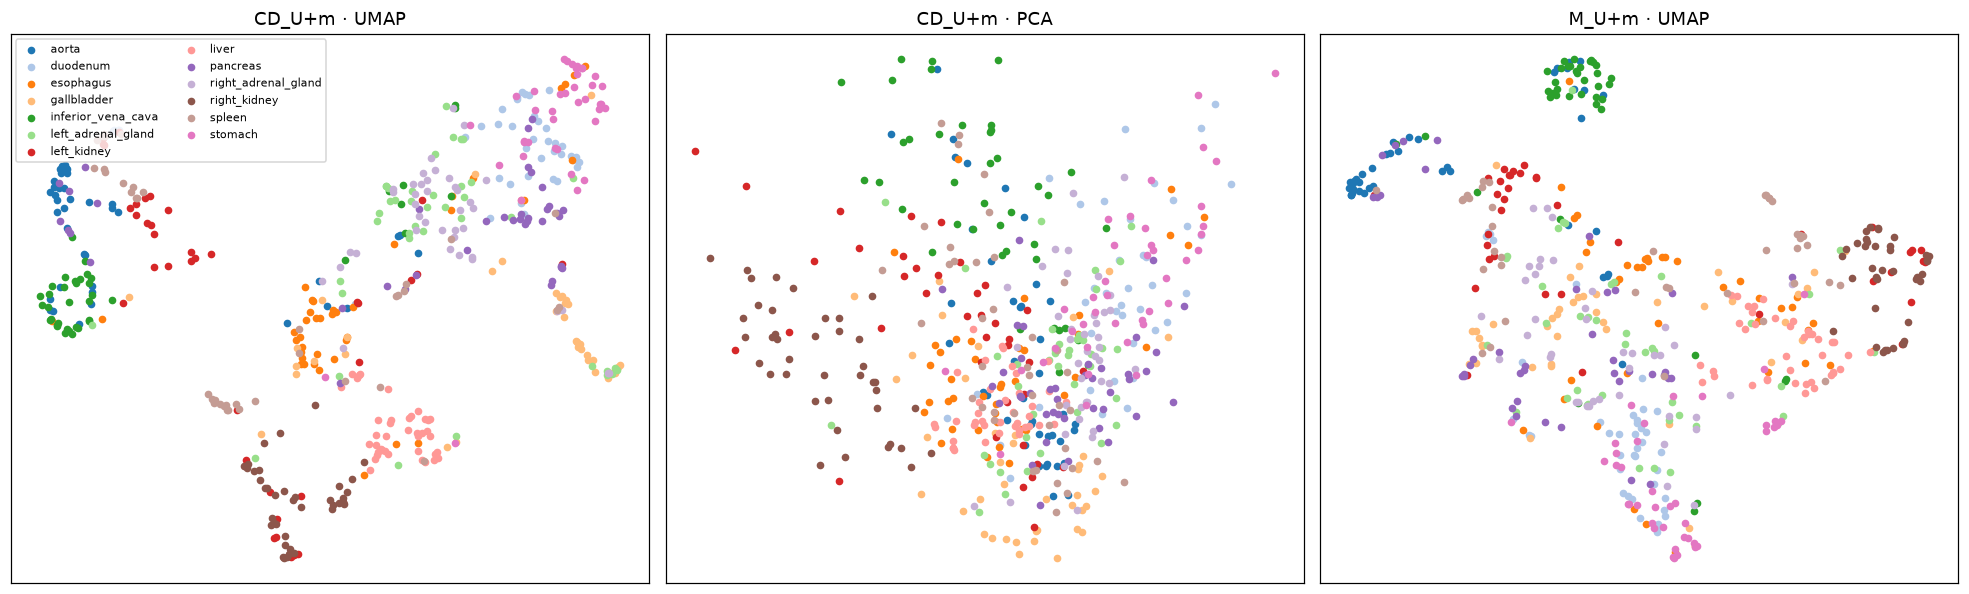

[figura] notebooks/figuras_aplicacion/05_nivel2_distancias_clases.png


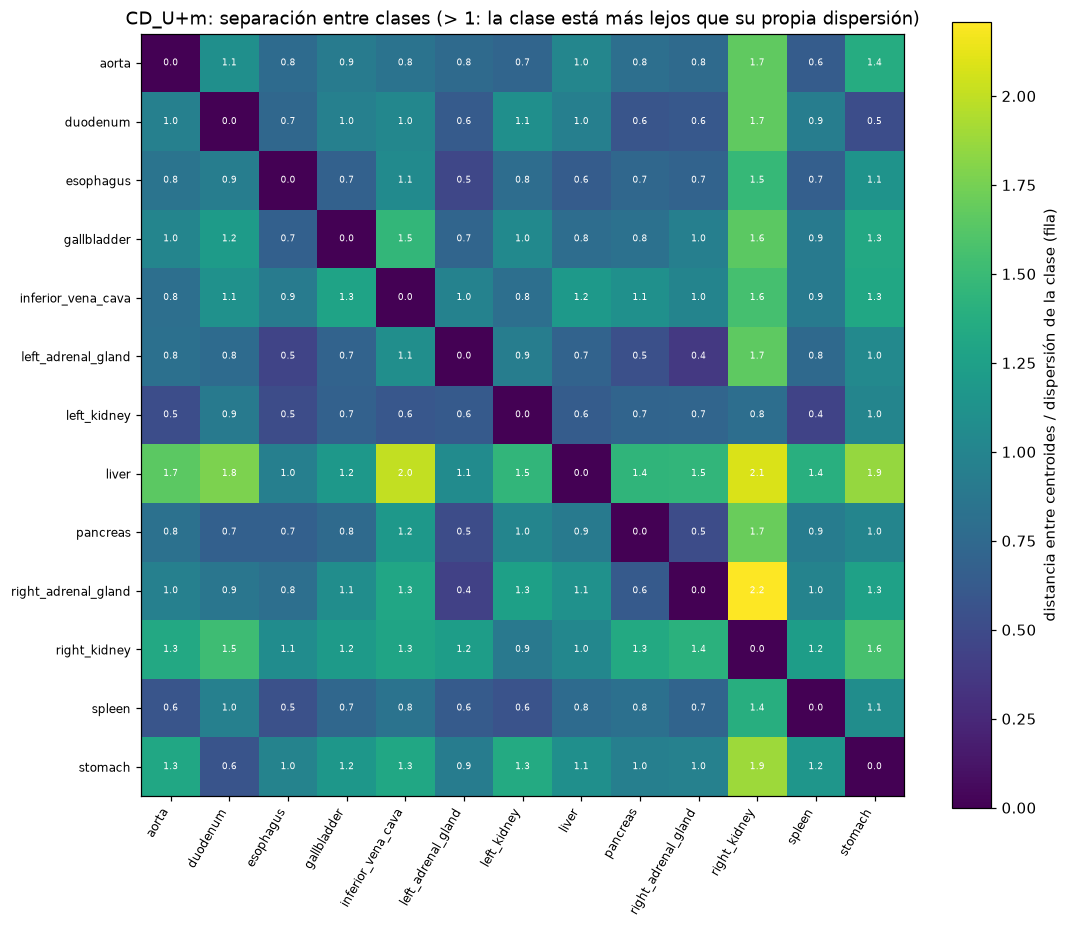

In [13]:
try:
    import umap
    UMAP_OK = True
except ImportError:
    UMAP_OK = False
    print("UMAP no instalado: se usará PCA para las vistas ilustrativas.")
fig, ax = plt.subplots(1, 3, figsize=(18, 5.5))
cm = plt.get_cmap("tab20")
for a, (m, metodo) in zip(ax, (("CD_U+m", "UMAP"), ("CD_U+m", "PCA"), ("M_U+m", "UMAP"))):
    Z = (umap.UMAP(n_neighbors=10, min_dist=0.1, random_state=SEMILLA).fit_transform(EMB[m]) if metodo == "UMAP" and UMAP_OK
         else PCA(2).fit_transform(EMB[m]))
    for k, c in enumerate(CLASES2):
        a.scatter(*Z[Y2 == k].T, s=16, color=cm(k % 20), label=c)
    a.set_title(f"{m} · {metodo if metodo != 'UMAP' or UMAP_OK else 'PCA (alternativa)'}"); a.set_xticks([]); a.set_yticks([])
ax[0].legend(fontsize=7, ncol=2, loc="best")
plt.tight_layout(); guardar(fig, "nivel2_embedding"); plt.show()

# Distancias entre centroides de clase en el embedding CD_U+m: ¿qué órganos se parecen?
F = EMB["CD_U+m"]; Cc = np.array([F[Y2 == k].mean(0) for k in range(len(CLASES2))])
Dc = np.sqrt(((Cc[:, None] - Cc[None]) ** 2).sum(-1)); disp = np.array([np.sqrt(((F[Y2 == k] - Cc[k]) ** 2).sum(1)).mean() for k in range(len(CLASES2))])
fig, ax = plt.subplots(figsize=(0.55 * len(CLASES2) + 3, 0.5 * len(CLASES2) + 2))
im = ax.imshow(Dc / np.maximum(disp[:, None], 1e-12), cmap="viridis"); ax.set_xticks(range(len(CLASES2))); ax.set_yticks(range(len(CLASES2)))
ax.set_xticklabels(CLASES2, rotation=60, ha="right", fontsize=8); ax.set_yticklabels(CLASES2, fontsize=8)
for i in range(len(CLASES2)):
    for j in range(len(CLASES2)): ax.text(j, i, f"{Dc[i, j] / max(disp[i], 1e-12):.1f}", ha="center", va="center", fontsize=6, color="w")
plt.colorbar(im, ax=ax, label="distancia entre centroides / dispersión de la clase (fila)")
ax.set_title("CD_U+m: separación entre clases (> 1: la clase está más lejos que su propia dispersión)"); ax.grid(False)
plt.tight_layout(); guardar(fig, "nivel2_distancias_clases"); plt.show()

[figura] notebooks/figuras_aplicacion/06_nivel2_vecinos.png


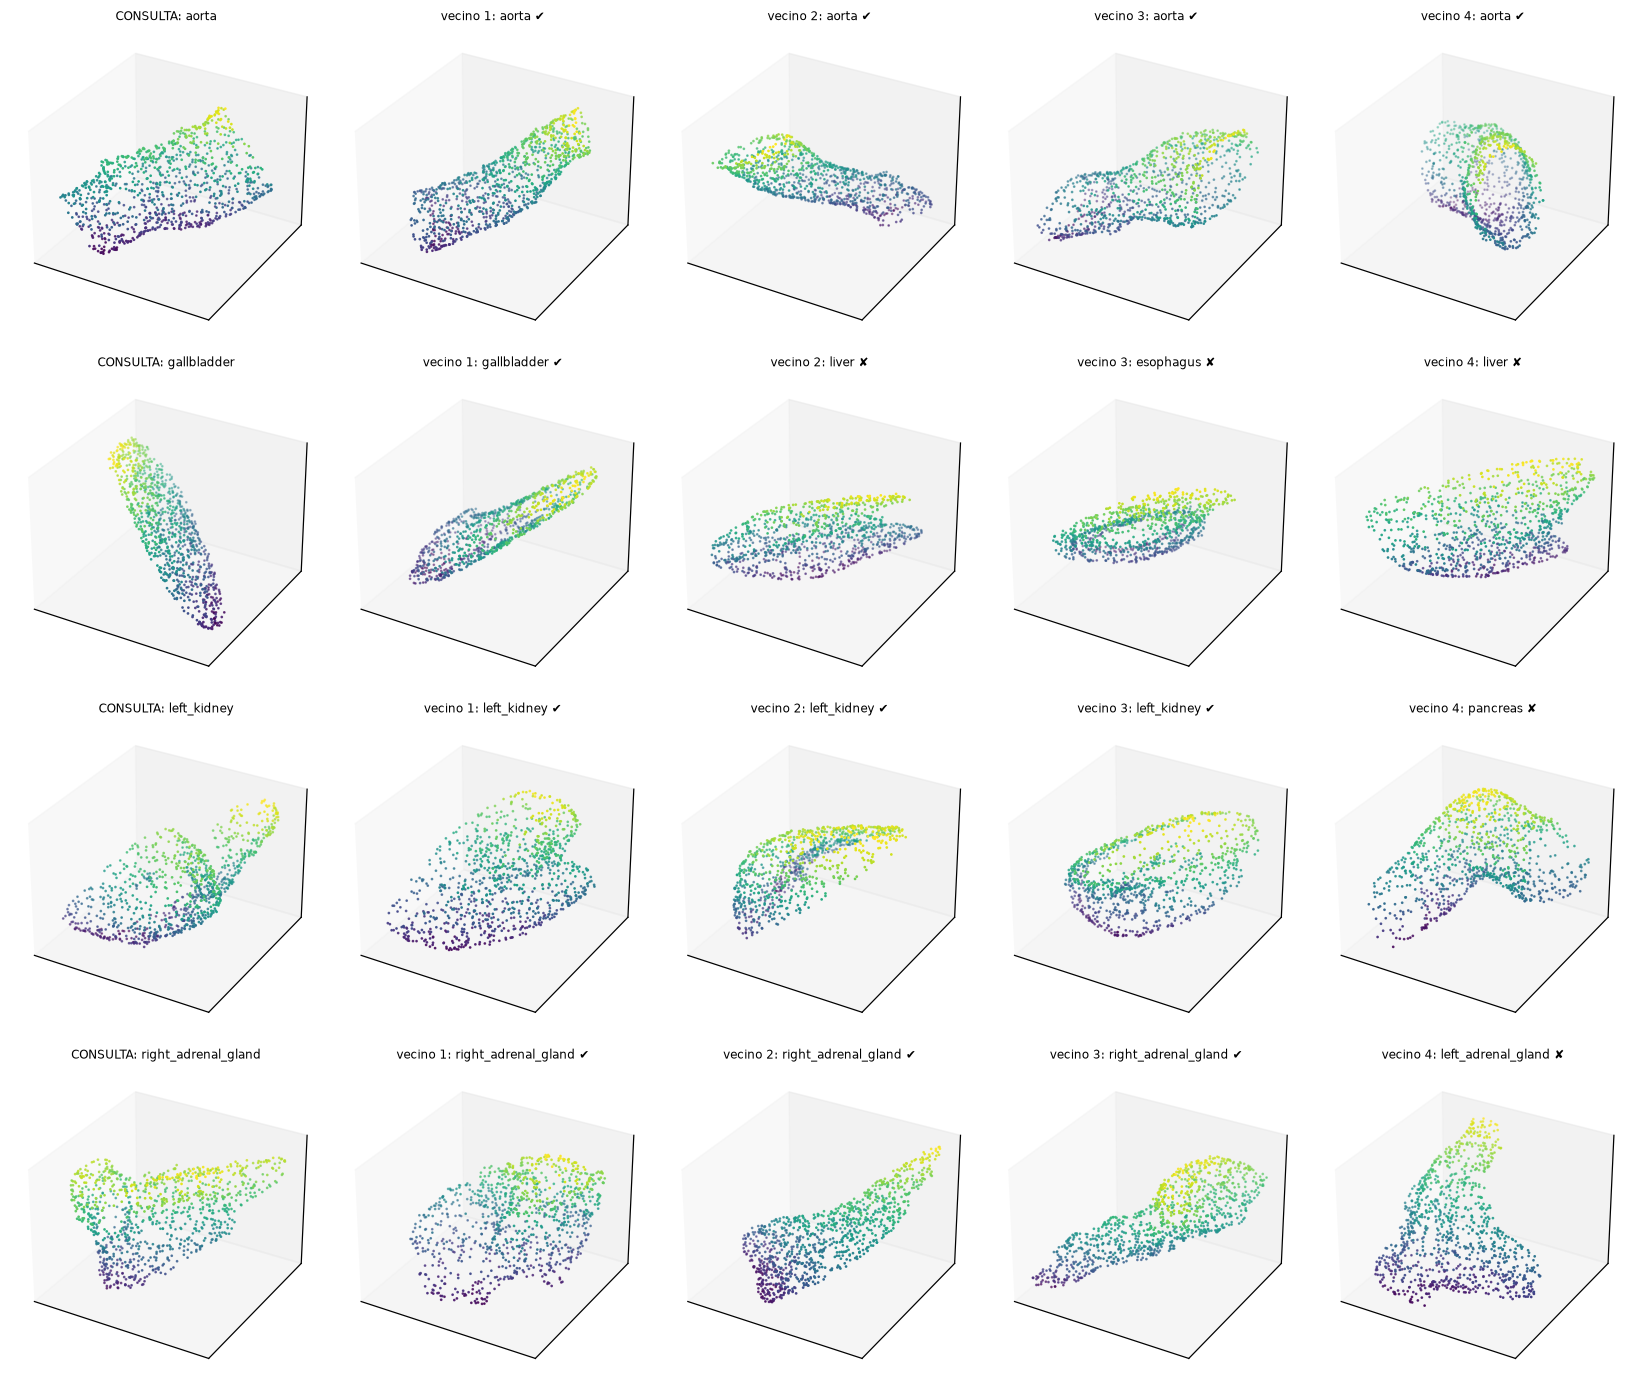

In [14]:
# Vecinos más cercanos de algunas formas (CD_U+m)
_, _, D = ap_loo(EMB["CD_U+m"], Y2)
consultas = [int(np.flatnonzero(Y2 == k)[0]) for k in range(0, len(CLASES2), max(1, len(CLASES2) // 4))][:4]
fig = plt.figure(figsize=(15, 3.2 * len(consultas)))
for i, q in enumerate(consultas):
    vec = np.argsort(D[q])[:4]
    for j, o in enumerate([q, *vec]):
        a = fig.add_subplot(len(consultas), 5, 5 * i + j + 1, projection="3d"); X = NUBES[o]
        a.scatter(*X.T, s=0.6, c=X[:, 2], cmap="viridis"); a.set_xticks([]); a.set_yticks([]); a.set_zticks([])
        ok = "" if j == 0 else (" ✔" if Y2[o] == Y2[q] else " ✘")
        a.set_title(("CONSULTA: " if j == 0 else f"vecino {j}: ") + CLASES2[Y2[o]] + ok, fontsize=8)
plt.tight_layout(); guardar(fig, "nivel2_vecinos"); plt.show()

**Nivel 2 · agrupamiento de formas**

ARI    NMI
descriptor agrupamiento                
D2         K-Means         0.115  0.283
           Ward            0.124  0.286
           Espectral k-NN  0.115  0.308
M_U+m      K-Means         0.174  0.369
           Ward            0.170  0.373
           Espectral k-NN  0.235  0.426
CD_U+m     K-Means         0.268  0.469
           Ward            0.246  0.466
           Espectral k-NN  0.312  0.520

[figura] notebooks/figuras_aplicacion/07_nivel2_confusion.png


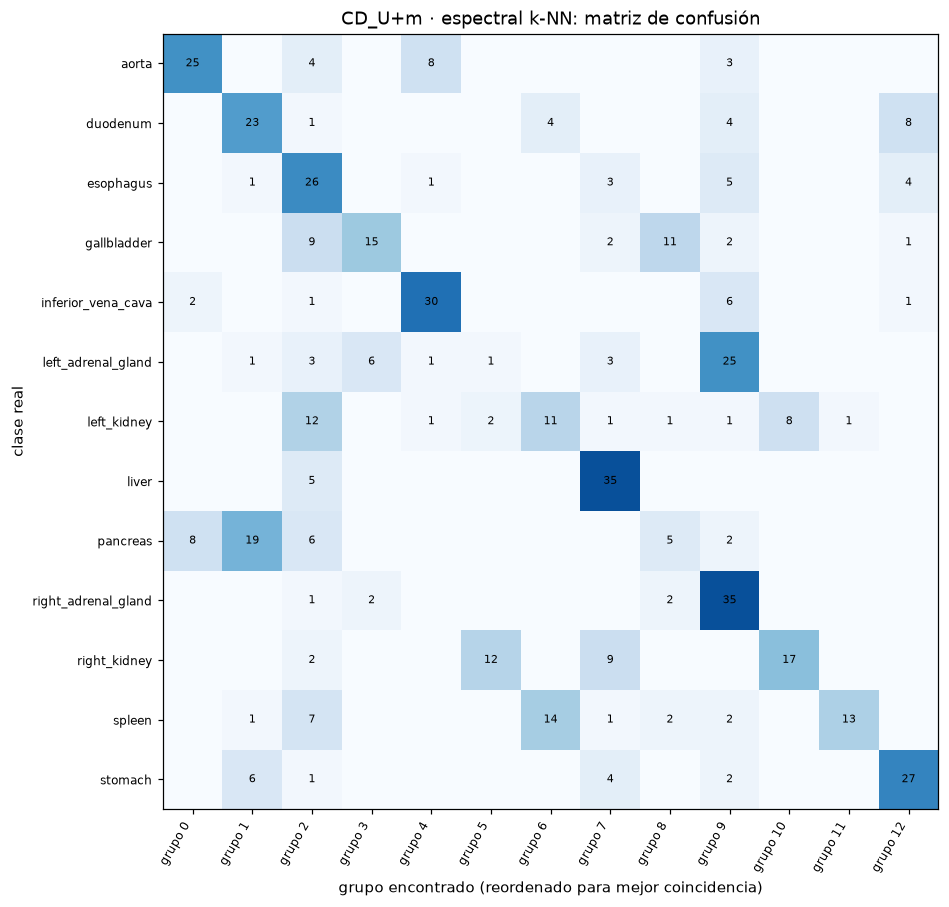

In [15]:
# Agrupamiento de las formas sin etiquetas (K = número de clases) y matriz de confusión
K2 = len(CLASES2); filas = []
for m in ("D2", "M_U+m", "CD_U+m"):
    for nombre, mod in (("K-Means", KMeans(K2, n_init=10, random_state=SEMILLA)), ("Ward", AgglomerativeClustering(K2)),
                        ("Espectral k-NN", SpectralClustering(K2, affinity="nearest_neighbors", n_neighbors=10, random_state=SEMILLA))):
        lab = mod.fit_predict(EMB[m])
        filas.append({"descriptor": m, "agrupamiento": nombre, "ARI": adjusted_rand_score(Y2, lab), "NMI": normalized_mutual_info_score(Y2, lab)})
AGR2 = pd.DataFrame(filas).set_index(["descriptor", "agrupamiento"]); tabla(AGR2, 3, "Nivel 2 · agrupamiento de formas")

lab = SpectralClustering(K2, affinity="nearest_neighbors", n_neighbors=10, random_state=SEMILLA).fit_predict(EMB["CD_U+m"])
C = pd.crosstab(Y2, lab).reindex(index=range(K2), columns=range(K2), fill_value=0).values
fi, co = linear_sum_assignment(-C); C = C[:, co[np.argsort(fi)]]
fig, ax = plt.subplots(figsize=(0.5 * K2 + 3, 0.45 * K2 + 2.5))
ax.imshow(C / np.maximum(C.sum(1, keepdims=True), 1), cmap="Blues", vmin=0, vmax=1)
for i in range(K2):
    for j in range(K2):
        if C[i, j]: ax.text(j, i, C[i, j], ha="center", va="center", fontsize=7)
ax.set_yticks(range(K2)); ax.set_yticklabels(CLASES2, fontsize=8); ax.set_xticks(range(K2)); ax.set_xticklabels([f"grupo {j}" for j in range(K2)], rotation=60, ha="right", fontsize=8)
ax.set_xlabel("grupo encontrado (reordenado para mejor coincidencia)"); ax.set_ylabel("clase real"); ax.grid(False)
ax.set_title("CD_U+m · espectral k-NN: matriz de confusión"); plt.tight_layout(); guardar(fig, "nivel2_confusion"); plt.show()

### **5.1 Robustez: formas incompletas o ruidosas contra una galería limpia**

Cada forma se consulta perturbada (mismas perturbaciones de §5.3) contra todas las demás formas limpias.

In [16]:
from sklearn.metrics import pairwise_distances
r3 = rng_(7); filas = []
for cond in ("clean", "noise", "density", "occlusion", "outliers"):
    Q = [perturb(x, cond, r3) for x in NUBES]
    FQ = {"CD_U": sc["CD_U"].transform(np.array([cd(x) for x in Q])), "M_U": sc["M_U"].transform(np.array([moment_descriptor(x) for x in Q])),
          "D2": np.array([d2_histogram(x) for x in Q])}
    FQ["CD_U+m"] = MET["CD_U"].transform(FQ["CD_U"]); FQ["M_U+m"] = MET["M_U"].transform(FQ["M_U"])
    for m in ("D2", "M_U+m", "CD_U+m"):
        D = pairwise_distances(FQ[m], EMB[m], metric="euclidean"); np.fill_diagonal(D, np.inf)
        idx = np.arange(len(Y2))
        ap = np.array([average_precision(D[i][idx != i], (Y2 == Y2[i])[idx != i]) for i in idx])
        filas.append({"condición": cond, "descriptor": m, "mAP": np.nanmean(ap)})
ROB = pd.DataFrame(filas).pivot(index="descriptor", columns="condición", values="mAP")[["clean", "noise", "density", "occlusion", "outliers"]]
tabla(ROB, 3, "Nivel 2 · mAP bajo perturbaciones de la consulta")

**Nivel 2 · mAP bajo perturbaciones de la consulta**

condición,clean,noise,density,occlusion,outliers
descriptor,,,,,
CD_U+m,0.326,0.309,0.282,0.248,0.175
D2,0.201,0.200,0.187,0.173,0.196
M_U+m,0.282,0.282,0.259,0.221,0.157


---
## **6. Resumen y exportación**

In [17]:
mej = N1.groupby("método").ARI.mean().sort_values(ascending=False)
_E = ENV[ENV.grado == GRADO_FIGURA]
env_v1 = _E[_E.grupos == "grupos de V1"][["cobertura", "invasión", "pureza"]].mean()
env_gt = _E[_E.grupos == "grupos reales"][["cobertura", "invasión", "pureza"]].mean()
c = CONTRASTES2.loc["CD_U+m − M_U+m"]
texto = f'''**Resultados generados con {DATASET}** ({len(FORMAS)} formas, {len(resumen)} clases; escenas {"anatómicas verificadas" if ALINEADO else "sintéticas compuestas en rejilla"}).

- **Nivel 1.** ARI medio sobre {len(PACIENTES)} índices de muestra: {", ".join(f"{k} {v:.2f}" for k, v in mej.items())}.
- **Envolventes (grado {GRADO_FIGURA}, percentil {PERCENTIL_ENVOLVENTE}).** Con los grupos de V1: cobertura {env_v1.cobertura:.2f}, invasión {env_v1['invasión']:.3f}, pureza {env_v1.pureza:.2f}. Con los grupos reales: cobertura {env_gt.cobertura:.2f}, invasión {env_gt['invasión']:.3f}, pureza {env_gt.pureza:.2f}.
- **Nivel 2.** mAP: {", ".join(f"{k} {v:.3f}" for k, v in N2.mAP.items())} (recuperación leave-one-out transductiva). CD_U+m − M_U+m = {c['Δ mAP']:+.3f} [{c['IC bajo']:+.3f}, {c['IC alto']:+.3f}] → {c.lectura}.
- **Agrupamiento de formas.** Mejor ARI: {AGR2.ARI.idxmax()[0]} con {AGR2.ARI.idxmax()[1]} ({AGR2.ARI.max():.2f}).
'''
display(Markdown(texto))
if GUARDAR:
    RES.mkdir(parents=True, exist_ok=True)
    N1.to_csv(RES / f"aplicacion_{DATASET}_nivel1.csv", index=False)
    ENV.to_csv(RES / f"aplicacion_{DATASET}_envolventes.csv", index=False)
    N2.to_csv(RES / f"aplicacion_{DATASET}_nivel2.csv")
    CONTRASTES2.to_csv(RES / f"aplicacion_{DATASET}_contrastes.csv")
    AGR2.to_csv(RES / f"aplicacion_{DATASET}_agrupamiento_formas.csv")
    ROB.to_csv(RES / f"aplicacion_{DATASET}_robustez.csv")
    (RES / f"aplicacion_{DATASET}_resumen.md").write_text(texto, encoding="utf-8")
    print("CSV y resumen guardados en", RES.relative_to(RAIZ))

**Resultados generados con FLARE** (628 formas, 13 clases; escenas sintéticas compuestas en rejilla).

- **Nivel 1.** ARI medio sobre 6 índices de muestra: Espectral k-NN 1.00, K-Means 1.00, V1 · CD local 1.00, V0 · CD global 1.00, DBSCAN 0.94, OPTICS 0.48.
- **Envolventes (grado 4, percentil 95).** Con los grupos de V1: cobertura 0.95, invasión 0.000, pureza 1.00. Con los grupos reales: cobertura 0.95, invasión 0.000, pureza 1.00.
- **Nivel 2.** mAP: CD_U+m 0.326, M_U+m 0.282, M_U 0.264, CD_U 0.259, D2 0.201 (recuperación leave-one-out transductiva). CD_U+m − M_U+m = +0.044 [+0.038, +0.050] → CD mejor.
- **Agrupamiento de formas.** Mejor ARI: CD_U+m con Espectral k-NN (0.31).


CSV y resumen guardados en benchmarks/results


### **Cómo llevarlo a la tesis**

Sección sugerida: **6.10 Aplicación práctica: formas anatómicas (MedShapeNetCore · FLARE)**, con
(i) la galería por clase, (ii) la tabla de ARI del Nivel 1 y la figura de la escena, (iii) la tabla de envolventes y su figura,
(iv) la tabla de mAP/1-NN con los contrastes, (v) el embedding UMAP y la matriz de distancias entre clases, (vi) la tabla de robustez.

En la discusión conviene señalar: que la invariancia a reflexiones debe verificarse experimentalmente; que el Nivel 1 se realiza por defecto sobre escenas sintéticas separadas y **no** demuestra segmentación de órganos anatómicamente adyacentes; que el grado mayor proporciona una familia más expresiva pero no garantiza mejor cobertura ni precisión y puede empeorar el condicionamiento (§2.7). Reportar también el carácter transductivo de la recuperación y la necesidad futura de una partición por paciente verificado.